# Parte 2: fine-tuning (LoRA) do gerador de plano de testes

Função especializada: **gerar o plano de testes** do MiniCode. A hipótese e os critérios estão em `docs/hipotese_parte2.md` (escritos antes do treino).

* **Entrada:** o prompt que o agente envia (pedido, especificação e plano). **Saída:** JSON `{"casos": [{"criterio", "entrada", "esperado"}]}`.
* **Dados:** exercícios inventados por modelos professores; os valores `esperado` vêm da **execução** da solução de referência, nunca do modelo.
* **Treino:** LoRA sobre um Qwen2.5 pequeno. A loss é calculada **só na resposta** (o prompt recebe `-100`).

**Como usar**
1. Envie a pasta `dados` (com `exemplos_treino.jsonl`, `exemplos_validacao.jsonl`, `exemplos_teste.jsonl` e `entradas_reais.json`) para `/content/dados` do servidor do Colab (no VS Code: botão direito na pasta, *Upload to Colab*). O dataset não vai para o repositório.
2. Deixe `MODO = "teste"` e rode tudo: ele treina só 30 passos e estima quanto tempo o treino completo leva.
3. Mude para `MODO = "treino"` e rode de novo: treino completo, curvas de loss, e respostas do modelo base e do ajustado.

> **Por que LoRA funciona:** o peso original `W` fica congelado e aprendemos só `B·A` (rank `r`), com `W' = W + (alpha/r)·B·A`. `B` começa em zero, então o modelo começa idêntico ao original. Treinamos uma fração pequena dos parâmetros (impresso abaixo).

## 1. Configuração

In [1]:
!ls /content

adaptador_minicode.zip	dados  drive  saida  saida_v2  sample_data


In [2]:
MODO = "treino"            # "teste": 30 passos para medir a velocidade | "treino": treino completo + avaliação
MODELO = "Qwen/Qwen2.5-1.5B-Instruct"
PASTA_DADOS = "/content/dados"
PASTA_SAIDA = "/content/saida_v2"   # pasta própria desta versão: não sobrescreve nada de /content/saida

R, ALPHA, DROPOUT = 16, 32, 0.05
ALVOS = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
LR, EPOCAS = 2e-4, 3
MICRO_LOTE, ACUMULACAO = 1, 8        # lote efetivo = 8 exemplos
MAX_TOKENS_EXEMPLO = 3072            # exemplos maiores que isso são ignorados
FRACAO_DOS_DADOS = 1.0               # 0.25 e 0.5 para a curva de escala
MAX_MINUTOS = 200                     # o treino para sozinho se passar disso (o enunciado limita a ~90 min)
PASSOS_DO_TESTE = 30
SEMENTE = 0
AVALIAR_SINTETICO = True
USAR_MELHOR = True                   # no fim, volta ao ponto de menor perda de validação (escolha feita só pela validação, nunca pelo teste)

## 2. Ambiente

In [3]:
!pip install -q peft
!pip uninstall -y -q torchao   # a versão do Colab é velha demais para o peft e não é usada aqui
import base64, json, math, os, random, time, zlib

import torch
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForCausalLM, AutoTokenizer

assert torch.cuda.is_available(), "Sem GPU: no Colab, escolha um ambiente de execução com GPU."
USA_BF16 = torch.cuda.get_device_capability()[0] >= 8   # bf16 de verdade só a partir da Ampere (A100, L4); a T4 usa fp16
DTYPE = torch.bfloat16 if USA_BF16 else torch.float16
print("GPU:", torch.cuda.get_device_name(0), "| memória:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB | precisão:", "bf16" if USA_BF16 else "fp16")
random.seed(SEMENTE)
torch.manual_seed(SEMENTE)
os.makedirs(PASTA_SAIDA, exist_ok=True)

GPU: NVIDIA L4 | memória: 23.7 GB | precisão: bf16


## 3. Dados

In [4]:
def ler_jsonl(caminho):
    with open(caminho, encoding="utf-8") as f:
        return [json.loads(linha) for linha in f if linha.strip()]

treino = ler_jsonl(f"{PASTA_DADOS}/exemplos_treino.jsonl")
validacao = ler_jsonl(f"{PASTA_DADOS}/exemplos_validacao.jsonl")
teste_sintetico = ler_jsonl(f"{PASTA_DADOS}/exemplos_teste.jsonl")
entradas_reais = json.load(open(f"{PASTA_DADOS}/entradas_reais.json", encoding="utf-8"))

random.Random(SEMENTE).shuffle(treino)
treino = treino[: int(len(treino) * FRACAO_DOS_DADOS)]
print(f"treino {len(treino)} | validação {len(validacao)} | teste sintético {len(teste_sintetico)} | prompts reais (25 tarefas) {len(entradas_reais)}")

treino 754 | validação 79 | teste sintético 80 | prompts reais (25 tarefas) 60


## 4. Modelo com LoRA

In [5]:
tok = AutoTokenizer.from_pretrained(MODELO)
modelo = AutoModelForCausalLM.from_pretrained(MODELO, torch_dtype=DTYPE).to("cuda")
modelo.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})   # menos memória, um pouco mais lento
modelo.enable_input_require_grads()
modelo.config.use_cache = False

configuracao = LoraConfig(r=R, lora_alpha=ALPHA, lora_dropout=DROPOUT, target_modules=ALVOS, task_type="CAUSAL_LM")
modelo = get_peft_model(modelo, configuracao)
treinaveis = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
total = sum(p.numel() for p in modelo.parameters())
print(f"parâmetros treináveis: {treinaveis:,} de {total:,} ({100 * treinaveis / total:.2f}%)")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

parâmetros treináveis: 18,464,768 de 1,562,179,072 (1.18%)


## 5. Tokenização (loss só na resposta)

In [6]:
def tokenizar(exemplo):
    # o prompt usa o chat template do Qwen; a resposta termina com <|im_end|>. Os tokens do prompt recebem -100 (fora da loss).
    prompt = tok.apply_chat_template(exemplo["mensagens"], tokenize=False, add_generation_prompt=True)
    ids_prompt = tok(prompt, add_special_tokens=False)["input_ids"]
    ids_resposta = tok(exemplo["resposta"] + "<|im_end|>", add_special_tokens=False)["input_ids"]
    return ids_prompt + ids_resposta, [-100] * len(ids_prompt) + ids_resposta

def preparar(exemplos):
    prontos = [tokenizar(e) for e in exemplos]
    return [p for p in prontos if len(p[0]) <= MAX_TOKENS_EXEMPLO], sum(len(p[0]) > MAX_TOKENS_EXEMPLO for p in prontos)

dados_treino, ignorados_t = preparar(treino)
dados_val, ignorados_v = preparar(validacao)
tamanhos = sorted(len(i) for i, _ in dados_treino)
print(f"treino: {len(dados_treino)} exemplos ({ignorados_t} ignorados por tamanho) | validação: {len(dados_val)} ({ignorados_v} ignorados)")
print(f"tokens por exemplo: mediana {tamanhos[len(tamanhos) // 2]}, máximo {tamanhos[-1]} | tokens no treino: {sum(tamanhos):,}")

treino: 754 exemplos (0 ignorados por tamanho) | validação: 79 (0 ignorados)
tokens por exemplo: mediana 1246, máximo 2413 | tokens no treino: 962,834


## 6. Treino

In [7]:
def montar_lote(itens):
    n = max(len(i) for i, _ in itens)
    ids = torch.full((len(itens), n), tok.pad_token_id, dtype=torch.long)
    rotulos = torch.full((len(itens), n), -100, dtype=torch.long)
    mascara = torch.zeros((len(itens), n), dtype=torch.long)
    for k, (i, r) in enumerate(itens):
        ids[k, : len(i)], rotulos[k, : len(r)], mascara[k, : len(i)] = torch.tensor(i), torch.tensor(r), 1
    return ids.cuda(), rotulos.cuda(), mascara.cuda()


@torch.no_grad()
def perda_de_validacao():
    modelo.eval()
    soma, tokens = 0.0, 0
    for k in range(0, len(dados_val), 4):
        ids, rotulos, mascara = montar_lote(dados_val[k : k + 4])
        with torch.autocast("cuda", dtype=DTYPE):
            perda = modelo(input_ids=ids, attention_mask=mascara, labels=rotulos).loss
        n = int((rotulos[:, 1:] != -100).sum())
        soma, tokens = soma + float(perda) * n, tokens + n
    modelo.train()
    return soma / tokens


parametros = [p for p in modelo.parameters() if p.requires_grad]
otimizador = torch.optim.AdamW(parametros, lr=LR, weight_decay=0.0)
escala = torch.amp.GradScaler("cuda", enabled=not USA_BF16)

por_passo = MICRO_LOTE * ACUMULACAO
passos_por_epoca = math.ceil(len(dados_treino) / por_passo)
total_de_passos = passos_por_epoca * EPOCAS if MODO == "treino" else PASSOS_DO_TESTE
aquecimento = max(1, int(0.05 * total_de_passos))


def lr_do_passo(p):
    if p < aquecimento:
        return LR * (p + 1) / aquecimento
    progresso = (p - aquecimento) / max(1, total_de_passos - aquecimento)
    return LR * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progresso)))


historico = {"passo": [], "perda_treino": [], "passo_val": [], "perda_val": [], "minutos": []}
print(f"modo {MODO}: {total_de_passos} passos ({passos_por_epoca} por época x {EPOCAS} épocas)" if MODO == "treino" else f"modo teste: {total_de_passos} passos")

torch.cuda.reset_peak_memory_stats()
modelo.train()
inicio, passo, tokens_vistos, parou_por_tempo = time.time(), 0, 0, False
melhor_val, melhor_passo, melhor_estado = float("inf"), 0, None
ordem_rng = random.Random(SEMENTE)

while passo < total_de_passos and not parou_por_tempo:
    ordem = list(range(len(dados_treino)))
    ordem_rng.shuffle(ordem)
    for k in range(0, len(ordem), por_passo):
        if passo >= total_de_passos:
            break
        for g in otimizador.param_groups:
            g["lr"] = lr_do_passo(passo)
        perda_do_passo = 0.0
        for m in range(k, min(k + por_passo, len(ordem)), MICRO_LOTE):
            itens = [dados_treino[j] for j in ordem[m : m + MICRO_LOTE]]
            ids, rotulos, mascara = montar_lote(itens)
            with torch.autocast("cuda", dtype=DTYPE):
                perda = modelo(input_ids=ids, attention_mask=mascara, labels=rotulos).loss / ACUMULACAO
            escala.scale(perda).backward()
            perda_do_passo += float(perda)
            tokens_vistos += int(mascara.sum())
        escala.unscale_(otimizador)
        torch.nn.utils.clip_grad_norm_(parametros, 1.0)
        escala.step(otimizador)
        escala.update()
        otimizador.zero_grad(set_to_none=True)
        passo += 1

        minutos = (time.time() - inicio) / 60
        historico["passo"].append(passo)
        historico["perda_treino"].append(perda_do_passo)
        historico["minutos"].append(minutos)
        if MODO == "treino" and (passo % 25 == 0 or passo == total_de_passos):
            historico["passo_val"].append(passo)
            historico["perda_val"].append(perda_de_validacao())
            if historico["perda_val"][-1] < melhor_val:
                melhor_val, melhor_passo = historico["perda_val"][-1], passo
                melhor_estado = {n: p.detach().cpu().clone() for n, p in modelo.named_parameters() if p.requires_grad}
        if MODO == "treino" and passo % passos_por_epoca == 0:
            pasta_epoca = f"{PASTA_SAIDA}/adaptador_epoca{passo // passos_por_epoca}"
            modelo.save_pretrained(pasta_epoca)
            print(f"adaptador da época {passo // passos_por_epoca} salvo em {pasta_epoca}")
        if passo % 5 == 0 or passo == total_de_passos:
            val = f" | validação {historico['perda_val'][-1]:.4f}" if historico["perda_val"] else ""
            print(f"passo {passo}/{total_de_passos} | perda {perda_do_passo:.4f}{val} | {minutos:.1f} min")
        if minutos > MAX_MINUTOS:
            print(f"parado: passou de {MAX_MINUTOS} minutos")
            parou_por_tempo = True
            break

segundos = time.time() - inicio
print(f"\n{passo} passos em {segundos / 60:.1f} min | {tokens_vistos / segundos:.0f} tokens/s | pico de memória {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")
if MODO == "teste":
    completo = segundos / passo * passos_por_epoca * EPOCAS / 60
    print(f"ESTIMATIVA do treino completo ({EPOCAS} épocas, {len(dados_treino)} exemplos): {completo:.0f} minutos (sem contar a validação e a avaliação)")

if MODO == "treino" and USAR_MELHOR and melhor_estado is not None:
    with torch.no_grad():
        for n, p in modelo.named_parameters():
            if n in melhor_estado:
                p.copy_(melhor_estado[n].to(p.device))
    print(f"modelo restaurado para o melhor ponto: passo {melhor_passo} (validação {melhor_val:.4f}); o adaptador salvo e avaliado é este")


modo treino: 285 passos (95 por época x 3 épocas)


/tmp/ipykernel_20199/1754646780.py:66: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  perda_do_passo += float(perda)


passo 5/285 | perda 0.1630 | 0.4 min
passo 10/285 | perda 0.1784 | 0.8 min
passo 15/285 | perda 0.1563 | 1.1 min
passo 20/285 | perda 0.1551 | 1.5 min
passo 25/285 | perda 0.1626 | validação 0.1650 | 1.9 min
passo 30/285 | perda 0.1217 | validação 0.1650 | 2.6 min
passo 35/285 | perda 0.1024 | validação 0.1650 | 2.9 min
passo 40/285 | perda 0.1464 | validação 0.1650 | 3.3 min
passo 45/285 | perda 0.1821 | validação 0.1650 | 3.7 min
passo 50/285 | perda 0.1347 | validação 0.1511 | 4.1 min
passo 55/285 | perda 0.0927 | validação 0.1511 | 4.7 min
passo 60/285 | perda 0.1438 | validação 0.1511 | 5.1 min
passo 65/285 | perda 0.1288 | validação 0.1511 | 5.5 min
passo 70/285 | perda 0.1418 | validação 0.1511 | 5.8 min
passo 75/285 | perda 0.1076 | validação 0.1461 | 6.2 min
passo 80/285 | perda 0.0895 | validação 0.1461 | 6.9 min
passo 85/285 | perda 0.1042 | validação 0.1461 | 7.2 min
passo 90/285 | perda 0.1322 | validação 0.1461 | 7.6 min


adaptador da época 1 salvo em /content/saida_v2/adaptador_epoca1
passo 95/285 | perda 0.0310 | validação 0.1461 | 7.9 min
passo 100/285 | perda 0.1357 | validação 0.1433 | 8.3 min
passo 105/285 | perda 0.0966 | validação 0.1433 | 9.0 min
passo 110/285 | perda 0.1078 | validação 0.1433 | 9.3 min
passo 115/285 | perda 0.0876 | validação 0.1433 | 9.7 min
passo 120/285 | perda 0.0937 | validação 0.1433 | 10.0 min
passo 125/285 | perda 0.0925 | validação 0.1450 | 10.4 min
passo 130/285 | perda 0.0974 | validação 0.1450 | 11.1 min
passo 135/285 | perda 0.0878 | validação 0.1450 | 11.5 min
passo 140/285 | perda 0.0660 | validação 0.1450 | 11.8 min
passo 145/285 | perda 0.0915 | validação 0.1450 | 12.2 min
passo 150/285 | perda 0.0665 | validação 0.1432 | 12.6 min
passo 155/285 | perda 0.0793 | validação 0.1432 | 13.2 min
passo 160/285 | perda 0.1188 | validação 0.1432 | 13.6 min
passo 165/285 | perda 0.0925 | validação 0.1432 | 14.0 min
passo 170/285 | perda 0.0955 | validação 0.1432 | 14.3 m

In [8]:
# Salva o modelo treinado logo depois do treino (antes da avaliação), para não perder o adaptador se algo falhar depois.
# O LoRA guarda só o adaptador (W' = W + BA); para usar, basta carregar o Qwen2.5-1.5B-Instruct base e aplicar este adaptador.
import shutil

if MODO == "treino":
    pasta_adaptador = f"{PASTA_SAIDA}/adaptador"
    modelo.save_pretrained(pasta_adaptador)
    tok.save_pretrained(pasta_adaptador)
    json.dump(historico, open(f"{PASTA_SAIDA}/historico.json", "w", encoding="utf-8"))
    arquivo_zip = shutil.make_archive("/content/adaptador_minicode_v2", "zip", pasta_adaptador)
    print(f"adaptador salvo em {pasta_adaptador} e compactado em {arquivo_zip} ({os.path.getsize(arquivo_zip) / 1e6:.0f} MB)")
    # cópia fora do Colab: tenta o Google Drive e o download direto; se falhar, baixe o zip pela aba de arquivos
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        os.makedirs("/content/drive/MyDrive/minicode_v2", exist_ok=True)
        shutil.copy(arquivo_zip, "/content/drive/MyDrive/minicode_v2/adaptador_minicode_v2.zip")
        shutil.copy(f"{PASTA_SAIDA}/historico.json", "/content/drive/MyDrive/minicode_v2/historico.json")
        print("copiado para o Google Drive: MyDrive/minicode_v2/adaptador_minicode_v2.zip")
    except Exception as erro:
        print("não copiou para o Drive:", type(erro).__name__, erro)
    try:
        from google.colab import files
        files.download(arquivo_zip)
    except Exception as erro:
        print("não baixou direto:", type(erro).__name__, "- baixe /content/adaptador_minicode_v2.zip pela aba de arquivos")
else:
    print("MODO teste: nada a salvar.")


adaptador salvo em /content/saida_v2/adaptador e compactado em /content/adaptador_minicode_v2.zip (71 MB)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
copiado para o Google Drive: MyDrive/minicode_v2/adaptador_minicode_v2.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Curvas de loss

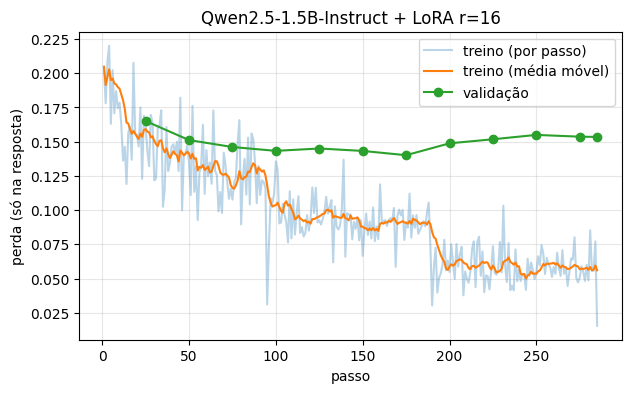

In [16]:
import matplotlib.pyplot as plt

def media_movel(valores, janela=10):
    return [sum(valores[max(0, i - janela + 1) : i + 1]) / len(valores[max(0, i - janela + 1) : i + 1]) for i in range(len(valores))]

plt.figure(figsize=(7, 4))
plt.plot(historico["passo"], historico["perda_treino"], alpha=0.3, label="treino (por passo)")
plt.plot(historico["passo"], media_movel(historico["perda_treino"]), label="treino (média móvel)")
if historico["perda_val"]:
    plt.plot(historico["passo_val"], historico["perda_val"], "o-", label="validação")
plt.xlabel("passo"); plt.ylabel("perda (só na resposta)"); plt.legend(); plt.grid(alpha=0.3)
plt.title(f"{MODELO.split('/')[-1]} + LoRA r={R}")
plt.savefig(f"{PASTA_SAIDA}/curvas_de_loss.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Respostas do modelo base e do ajustado (só em `MODO = "treino"`)

Os mesmos prompts, com e sem o adaptador LoRA, gerados com decodificação gulosa. A conferência dos valores esperados é feita depois, localmente, com o oráculo (a solução de referência de cada tarefa).

In [10]:
def prompt_de(mensagens):
    return tok.apply_chat_template(mensagens, tokenize=False, add_generation_prompt=True)


@torch.no_grad()
def gerar_respostas(listas_de_mensagens, lote=8, max_novos=2000):
    modelo.eval()
    modelo.config.use_cache = True
    tok.padding_side = "left"
    prompts = [prompt_de(m) for m in listas_de_mensagens]
    ordem = sorted(range(len(prompts)), key=lambda i: len(prompts[i]))
    respostas = [None] * len(prompts)
    for k in range(0, len(ordem), lote):
        indices = ordem[k : k + lote]
        entrada = tok([prompts[i] for i in indices], return_tensors="pt", padding=True, add_special_tokens=False).to("cuda")
        with torch.autocast("cuda", dtype=DTYPE):
            saida = modelo.generate(**entrada, max_new_tokens=max_novos, do_sample=False, pad_token_id=tok.pad_token_id)
        for i, s in zip(indices, saida):
            respostas[i] = tok.decode(s[entrada["input_ids"].shape[1] :], skip_special_tokens=True)
        print(f"  {min(k + lote, len(ordem))}/{len(ordem)} gerados")
    return respostas


def imprimir_para_copiar(nome, objeto):
    # texto compacto (zlib + base64) para ler as respostas direto da saída do notebook
    texto = base64.b64encode(zlib.compress(json.dumps(objeto, ensure_ascii=False).encode("utf-8"))).decode()
    partes = [texto[i : i + 20000] for i in range(0, len(texto), 20000)]
    for n, parte in enumerate(partes, start=1):
        print(f"RESULTADO {nome} {n}/{len(partes)} {parte}")


if MODO == "treino":
    modelo.save_pretrained(f"{PASTA_SAIDA}/adaptador")
    prompts_reais = [e["mensagens"] for e in entradas_reais]
    resultado = {"modelo": MODELO, "r": R, "alpha": ALPHA, "epocas": EPOCAS, "exemplos_de_treino": len(dados_treino), "historico": historico,
                 "minutos_de_treino": segundos / 60, "parou_por_tempo": parou_por_tempo}
    print("prompts reais, ajustado")
    resultado["real_ajustado"] = gerar_respostas(prompts_reais)
    print("prompts reais, base")
    with modelo.disable_adapter():
        resultado["real_base"] = gerar_respostas(prompts_reais)
    if AVALIAR_SINTETICO:
        prompts_sint = [e["mensagens"] for e in teste_sintetico]
        print("teste sintético, ajustado")
        resultado["sintetico_ajustado"] = gerar_respostas(prompts_sint)
        print("teste sintético, base")
        with modelo.disable_adapter():
            resultado["sintetico_base"] = gerar_respostas(prompts_sint)
    nome_do_arquivo = f"{PASTA_SAIDA}/resultado_{FRACAO_DOS_DADOS}.json"
    json.dump(resultado, open(nome_do_arquivo, "w", encoding="utf-8"), ensure_ascii=False)
    try:
        import shutil
        os.makedirs("/content/drive/MyDrive/minicode_v2", exist_ok=True)
        shutil.copy(nome_do_arquivo, "/content/drive/MyDrive/minicode_v2/")
        print("resultado copiado para o Drive: MyDrive/minicode_v2/")
    except Exception as erro:
        print("não copiou o resultado para o Drive:", type(erro).__name__, erro)
    imprimir_para_copiar(f"fracao_{FRACAO_DOS_DADOS}", resultado)
else:
    print("MODO teste: nada a avaliar. Mude MODO para 'treino' para o treino completo.")

prompts reais, ajustado
  8/60 gerados
  16/60 gerados
  24/60 gerados
  32/60 gerados
  40/60 gerados
  48/60 gerados
  56/60 gerados
  60/60 gerados
prompts reais, base
  8/60 gerados
  16/60 gerados
  24/60 gerados
  32/60 gerados
  40/60 gerados
  48/60 gerados
  56/60 gerados
  60/60 gerados
teste sintético, ajustado
  8/80 gerados
  16/80 gerados
  24/80 gerados
  32/80 gerados
  40/80 gerados
  48/80 gerados
  56/80 gerados
  64/80 gerados
  72/80 gerados
  80/80 gerados
teste sintético, base
  8/80 gerados
  16/80 gerados
  24/80 gerados
  32/80 gerados
  40/80 gerados
  48/80 gerados
  56/80 gerados
  64/80 gerados
  72/80 gerados
  80/80 gerados
resultado copiado para o Drive: MyDrive/minicode_v2/
RESULTADO fracao_1.0 1/4 ...
RESULTADO fracao_1.0 2/4 ...
RESULTADO fracao_1.0 3/4 ...
RESULTADO fracao_1.0 4/4 8asNP+3k2cV0lr5qAslg+PbQxfbQxfZV0gyjwvRxF+NDF+P48QCSot8FCsrNDKEtH8larfVk2mLFCFriezfh5PjYwcnxsYMTZulgAhOgJlzFm04mOuxHsQyXq6K739930MbuOoj7LFsGf8rYxNsSeYST0GH2a8dBBN53kPFsNYN

In [17]:
# Salva no Google Drive tudo que o treino da train_checkpoints produziu: adaptadores (melhor ponto e por época), respostas e gráficos.
import os, shutil

DESTINO = "/content/drive/MyDrive/minicode_v2"
TEMP = "/content/zips_v2"
os.makedirs(DESTINO, exist_ok=True)
os.makedirs(TEMP, exist_ok=True)

try:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
except Exception as erro:
    print("Drive:", type(erro).__name__, erro)

# 1) adaptadores: o melhor ponto (o que foi avaliado) e os de cada época. Cada pasta vira um zip.
adaptadores = {
    "adaptador_melhor_ponto": f"{PASTA_SAIDA}/adaptador",
    "adaptador_epoca1": f"{PASTA_SAIDA}/adaptador_epoca1",
    "adaptador_epoca2": f"{PASTA_SAIDA}/adaptador_epoca2",
    "adaptador_epoca3": f"{PASTA_SAIDA}/adaptador_epoca3",
}
for nome, pasta in adaptadores.items():
    if os.path.isdir(pasta):
        zip_local = shutil.make_archive(f"{TEMP}/{nome}", "zip", pasta)
        shutil.copy(zip_local, f"{DESTINO}/{nome}.zip")
        print(f"ok  {nome}.zip  ({os.path.getsize(zip_local) / 1e6:.0f} MB)")
    else:
        print(f"NÃO EXISTE {pasta}")

# 2) arquivos soltos: respostas da avaliação, histórico de perdas, curva de loss
for arquivo in sorted(os.listdir(PASTA_SAIDA)):
    caminho = f"{PASTA_SAIDA}/{arquivo}"
    if os.path.isfile(caminho):
        shutil.copy(caminho, f"{DESTINO}/{arquivo}")
        print(f"ok  {arquivo}  ({os.path.getsize(caminho) / 1e6:.2f} MB)")

# 3) confere o que ficou no Drive (tamanho de cada arquivo)
print("\nNo Drive:", DESTINO)
for arquivo in sorted(os.listdir(DESTINO)):
    print(f"  {arquivo}  {os.path.getsize(f'{DESTINO}/{arquivo}') / 1e6:.2f} MB")

ok  adaptador_melhor_ponto.zip  (71 MB)
ok  adaptador_epoca1.zip  (68 MB)
ok  adaptador_epoca2.zip  (68 MB)
ok  adaptador_epoca3.zip  (68 MB)
ok  curvas_de_loss.png  (0.11 MB)
ok  historico.json  (0.01 MB)
ok  resultado_1.0.json  (0.37 MB)

No Drive: /content/drive/MyDrive/minicode_v2
  adaptador_epoca1.zip  68.41 MB
  adaptador_epoca2.zip  68.40 MB
  adaptador_epoca3.zip  68.40 MB
  adaptador_melhor_ponto.zip  70.54 MB
  adaptador_minicode_v2.zip  70.54 MB
  curvas_de_loss.png  0.11 MB
  historico.json  0.01 MB
  resultado_1.0.json  0.37 MB
